# Comparaison des trois modèles pour le BO « aide à la conduite »

**Objectif métier (BO).** Aider un système d'aide à la conduite à repérer et localiser tout obstacle inattendu sur la chaussée, pour déclencher une alerte. **Ne pas rater d'obstacle** compte plus que d'éviter les fausses alertes : le **rappel** est le critère principal, la **précision** au même rappel mesure le coût en fausses alertes.

**Protocole identique pour les trois modèles** (sinon la comparaison ne vaut rien) :
- mêmes images, même découpage `split.csv`, même résolution 512×288 ;
- le **seuil est choisi sur la validation** (jamais sur le test), puis les métriques sont lues sur le **test** ;
- deux modes de seuil : *Dice maximal* (le seuil des notebooks d'entraînement) et *rappel cible* (seuil le plus élevé qui atteint le rappel visé sur la validation, donc le moins de fausses alertes possible) ;
- taille et temps d'inférence mesurés dans les mêmes conditions (CPU, 1 image).

**Modèles comparés :** U-Net ResNet34 pré-entraîné (`01`), U-Net ResNet34 from scratch (`02`), encodeur-décodeur CNN simple from scratch (`03`). Ce notebook n'entraîne rien : il charge les trois fichiers `.pt`.

**Pour l'exécuter :** depuis `RoadAnomaly\RoadAnomaly`, kernel *RoadAnomaly venv*, *Run All*. Ne rien lancer d'autre en même temps, pour que les temps d'inférence soient fiables.

In [1]:
import os, re, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from scipy import ndimage
from sklearn.model_selection import train_test_split
from IPython.display import display

# OpenCV ne doit pas lancer ses propres threads (évite les conflits avec PyTorch)
cv2.setNumThreads(0)

print("PyTorch :", torch.__version__, "| smp :", smp.__version__)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Périphérique :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "pas de GPU (l'entraînement sera lent)")

c:\Projects\deep_learning\RoadAnomaly\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch : 2.15.0+cpu | smp : 0.6.0
Périphérique : cpu | pas de GPU (l'entraînement sera lent)


In [2]:
# ============================================================
# CONFIGURATION
# ============================================================
SEED = 42
IMG_W, IMG_H = 512, 288               # même résolution que les trois entraînements
TARGET_RECALLS = [0.80, 0.90]         # rappels visés pour le BO (modifiables)
DETECT_RECALL = 0.50                  # une image compte comme « obstacle détecté » si au moins 50 % de ses pixels d'anomalie sont retrouvés

# Dossier de chaque modèle (relatif au dossier RoadAnomaly\RoadAnomaly) et type d'architecture
MODELS = {
    "U-Net ResNet34 pré-entraîné":        {"dir": "outputs_unet_resnet34_pretrained", "ckpt": "unet_resnet34_pretrained_best.pt", "kind": "unet"},
    "U-Net ResNet34 from scratch":        {"dir": "outputs_unet_resnet34_scratch",    "ckpt": "unet_resnet34_scratch_best.pt",    "kind": "unet"},
    "Encodeur-décodeur CNN from scratch": {"dir": "outputs_cnn_encdec_scratch",       "ckpt": "cnn_encdec_scratch_best.pt",       "kind": "cnn"},
}

def find_data_root():
    """Remonte l'arborescence jusqu'au dossier du dataset (frames/ + frame_list.json)."""
    here = os.path.abspath(os.getcwd())
    for _ in range(6):
        for cand in (here, os.path.join(here, "RoadAnomaly")):
            if os.path.exists(os.path.join(cand, "frames")) and os.path.exists(os.path.join(cand, "frame_list.json")):
                return cand
        here = os.path.dirname(here)
    raise FileNotFoundError(f"Dataset introuvable depuis {os.getcwd()} : ouvrir le notebook depuis le dépôt du projet.")

ROOT = find_data_root()
FRAMES = os.path.join(ROOT, "frames")
OUT_DIR = os.path.join(ROOT, "outputs_comparaison_bo")
os.makedirs(OUT_DIR, exist_ok=True)

for name, cfg in MODELS.items():
    cfg["path"] = os.path.join(ROOT, cfg["dir"], cfg["ckpt"])
    assert os.path.exists(cfg["path"]), f"Poids introuvables pour « {name} » : {cfg['path']}"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Dataset  :", ROOT)
print("Résultats:", OUT_DIR)
for name, cfg in MODELS.items(): print(" -", name, "->", cfg["dir"])

Dataset  : c:\Projects\deep_learning\RoadAnomaly\RoadAnomaly
Résultats: c:\Projects\deep_learning\RoadAnomaly\RoadAnomaly\outputs_comparaison_bo
 - U-Net ResNet34 pré-entraîné -> outputs_unet_resnet34_pretrained
 - U-Net ResNet34 from scratch -> outputs_unet_resnet34_scratch
 - Encodeur-décodeur CNN from scratch -> outputs_cnn_encdec_scratch


## 1. Données : même découpage que les entraînements

In [3]:
def get_paths(name):
    """Chemins de l'image et du masque à partir d'un nom de frame (avec ou sans .webp)."""
    base = os.path.splitext(name)[0]
    return base, os.path.join(FRAMES, base + ".webp"), os.path.join(FRAMES, base + ".labels", "labels_semantic.png")

def get_category(name):
    m = re.match(r"^([a-zA-Z_]+?)\d", name)
    return m.group(1) if m else "autre"

def build_split_df():
    """Recalcule le découpage exactement comme dans le notebook d'exploration."""
    with open(os.path.join(ROOT, "frame_list.json")) as f:
        frame_list = json.load(f)
    rows = []
    for name in frame_list:
        base, _, mask_p = get_paths(name)
        mask = np.array(Image.open(mask_p))
        rows.append({"name": base, "prop_anomalie": float((mask == 2).mean())})
    d = pd.DataFrame(rows)
    d["categorie"] = d["name"].apply(get_category)
    grandes = ["animals", "obstacles", "cones"]
    d["groupe"] = d["categorie"].apply(lambda c: c if c in grandes else "autres")
    seuil = d["prop_anomalie"].median()
    d["taille"] = np.where(d["prop_anomalie"] < seuil, "petite", "grande")
    d["strat"] = d["groupe"] + "_" + d["taille"]
    trainval, test = train_test_split(d, test_size=0.20, stratify=d["strat"], random_state=SEED)
    train, val = train_test_split(trainval, test_size=0.25, stratify=trainval["strat"], random_state=SEED)
    d["split"] = "train"
    d.loc[val.index, "split"] = "val"
    d.loc[test.index, "split"] = "test"
    return d

SPLIT_CSV = os.path.join(ROOT, "split.csv")
df_new = build_split_df()
if os.path.exists(SPLIT_CSV):
    df = pd.read_csv(SPLIT_CSV)
    same = dict(zip(df["name"], df["split"])) == dict(zip(df_new["name"], df_new["split"]))
    print("split.csv lu. Identique au découpage recalculé :", same)
else:
    df = df_new
    df[["name", "categorie", "groupe", "taille", "prop_anomalie", "split"]].to_csv(SPLIT_CSV, index=False)
    print("split.csv absent : découpage recalculé et sauvegardé.")

train_names = df[df["split"] == "train"]["name"].tolist()
val_names   = df[df["split"] == "val"]["name"].tolist()
test_names  = df[df["split"] == "test"]["name"].tolist()
all_names = train_names + val_names + test_names

# Pas de fuite de données : aucune image dans deux ensembles à la fois
assert not (set(train_names) & set(val_names)) and not (set(train_names) & set(test_names)) and not (set(val_names) & set(test_names))
assert len(set(all_names)) == len(df) == 60
print(f"train = {len(train_names)} | val = {len(val_names)} | test = {len(test_names)}")
print(pd.crosstab(df["split"], df["groupe"]))

split.csv lu. Identique au découpage recalculé : True
train = 36 | val = 12 | test = 12
groupe  animals  autres  cones  obstacles
split                                    
test          6       1      2          3
train        19       3      5          9
val           6       2      1          3


In [4]:
# Chargement en mémoire des 60 paires (image RGB, masque binaire 0/1) : ~220 Mo, entraînement bien plus rapide
def load_raw(name):
    _, img_p, mask_p = get_paths(name)
    img = np.array(Image.open(img_p).convert("RGB"))
    mask = (np.array(Image.open(mask_p)) == 2).astype(np.uint8)   # 2 (anomalie) -> 1, 0 (fond) -> 0
    assert img.shape[:2] == mask.shape, f"Image et masque de tailles différentes : {name}"
    return img, mask

CACHE = {n: load_raw(n) for n in all_names}
H_FULL, W_FULL = next(iter(CACHE.values()))[1].shape
print("Paires chargées :", len(CACHE), "| résolution d'origine :", (W_FULL, H_FULL))

Paires chargées : 60 | résolution d'origine : (1280, 720)


In [5]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def to_tensor(img_uint8):
    """Image uint8 (H, W, 3) -> tenseur float normalisé ImageNet (3, H, W) : même prétraitement que les entraînements."""
    x = (img_uint8.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())

## 2. Chargement des trois modèles

In [6]:
def conv_block(c_in, c_out, use_bn=True):
    """Deux convolutions 3x3 (+ BatchNorm optionnelle) + ReLU (identique au notebook 03)."""
    layers = [nn.Conv2d(c_in, c_out, 3, padding=1, bias=not use_bn)]
    if use_bn: layers.append(nn.BatchNorm2d(c_out))
    layers.append(nn.ReLU(inplace=True))
    layers.append(nn.Conv2d(c_out, c_out, 3, padding=1, bias=not use_bn))
    if use_bn: layers.append(nn.BatchNorm2d(c_out))
    layers.append(nn.ReLU(inplace=True))
    return nn.Sequential(*layers)

class EncoderDecoderCNN(nn.Module):
    """Encodeur-décodeur convolutif SANS connexions de saut (identique au notebook 03)."""
    def __init__(self, base=16, dropout=0.1, use_bn=True):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8]
        self.encoder = nn.ModuleList()
        c_prev = 3
        for c in ch:
            self.encoder.append(conv_block(c_prev, c, use_bn)); c_prev = c
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = nn.Sequential(conv_block(ch[-1], base * 16, use_bn), nn.Dropout2d(dropout))
        self.up, self.dec = nn.ModuleList(), nn.ModuleList()
        c_prev = base * 16
        for c in reversed(ch):
            self.up.append(nn.ConvTranspose2d(c_prev, c, kernel_size=2, stride=2))
            self.dec.append(conv_block(c, c, use_bn)); c_prev = c
        self.head = nn.Conv2d(ch[0], 1, kernel_size=1)
    def forward(self, x):
        for block in self.encoder:
            x = self.pool(block(x))
        x = self.bottleneck(x)
        for up, block in zip(self.up, self.dec):
            x = block(up(x))
        return self.head(x)

def load_model(kind, path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    if kind == "unet":
        m = smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=1)
    else:
        m = EncoderDecoderCNN(base=ck.get("base_channels", 16), use_bn=ck.get("use_bn", True))
    m.load_state_dict(ck["state_dict"])
    return m.to(DEVICE).eval(), ck

loaded = {}
for name, cfg in MODELS.items():
    model_, ck_ = load_model(cfg["kind"], cfg["path"])
    loaded[name] = model_
    print(f"{name:38s} | epoch retenue : {ck_.get('epoch')} | Dice validation à l'entraînement : {ck_.get('val_dice', float('nan')):.4f} | taille d'entrée : {ck_.get('img_size')}")

U-Net ResNet34 pré-entraîné            | epoch retenue : 35 | Dice validation à l'entraînement : 0.8992 | taille d'entrée : (512, 288)
U-Net ResNet34 from scratch            | epoch retenue : 39 | Dice validation à l'entraînement : 0.6780 | taille d'entrée : (512, 288)
Encodeur-décodeur CNN from scratch     | epoch retenue : 20 | Dice validation à l'entraînement : 0.6112 | taille d'entrée : (512, 288)


## 3. Prédictions et fonctions d'évaluation (reprises de `02`)

In [7]:
def metrics_from_counts(tp, fp, fn, eps=1e-9):
    """Métriques pixel à partir des comptes TP/FP/FN."""
    precision = tp / (tp + fp + eps)
    recall    = tp / (tp + fn + eps)
    f1        = 2 * precision * recall / (precision + recall + eps)
    iou       = tp / (tp + fp + fn + eps)
    dice      = 2 * tp / (2 * tp + fp + fn + eps)
    return {"iou": iou, "dice": dice, "precision": precision, "recall": recall, "f1": f1}

@torch.no_grad()
def predict_probs(model, names, bs=4):
    """Probabilités d'anomalie à la résolution d'origine, dict {nom: tableau float32 (H, W)}."""
    model.eval(); out = {}
    for i in range(0, len(names), bs):
        batch = names[i:i + bs]
        x = torch.stack([to_tensor(cv2.resize(CACHE[n][0], (IMG_W, IMG_H), interpolation=cv2.INTER_AREA)) for n in batch]).to(DEVICE)
        probs = torch.sigmoid(F.interpolate(model(x), size=(H_FULL, W_FULL), mode="bilinear", align_corners=False))
        for n, p in zip(batch, probs[:, 0].cpu().numpy()):
            out[n] = p.astype(np.float32)
    return out

def global_counts(names, probs, thr):
    tp = fp = fn = 0
    for n in names:
        gt, pred = CACHE[n][1].astype(bool), probs[n] >= thr
        tp += int((pred & gt).sum()); fp += int((pred & ~gt).sum()); fn += int((~pred & gt).sum())
    return tp, fp, fn

def sweep_threshold(names, probs, thresholds):
    rows = [{"thr": t, **metrics_from_counts(*global_counts(names, probs, t))} for t in thresholds]
    r = pd.DataFrame(rows)
    return r, float(r.loc[r["dice"].idxmax(), "thr"])

def evaluate(names, probs, thr):
    """Renvoie (métriques globales 'micro', tableau par image, moyennes par image 'macro')."""
    rows = []
    for n in names:
        gt, pred = CACHE[n][1].astype(bool), probs[n] >= thr
        tp, fp, fn = int((pred & gt).sum()), int((pred & ~gt).sum()), int((~pred & gt).sum())
        rows.append({"name": n, "tp": tp, "fp": fp, "fn": fn, **metrics_from_counts(tp, fp, fn)})
    per_img = pd.DataFrame(rows)
    glob = metrics_from_counts(per_img["tp"].sum(), per_img["fp"].sum(), per_img["fn"].sum())
    macro = per_img[["iou", "dice", "precision", "recall", "f1"]].mean().to_dict()
    return glob, per_img, macro

t0 = time.time()
PROBS = {name: {"val": predict_probs(m, val_names), "test": predict_probs(m, test_names)} for name, m in loaded.items()}
print(f"Prédictions des 3 modèles calculées en {time.time() - t0:.0f} s")

Prédictions des 3 modèles calculées en 10 s


## 4. Vérification : on retrouve les résultats des notebooks d'entraînement

Seuil au Dice maximal sur la validation, métriques sur le test. Les valeurs doivent correspondre à celles de `resultats_unet.json` de chaque modèle. Si l'écart est grand, le mauvais fichier `.pt` a été chargé ou la résolution est différente.

In [8]:
thr_grid = np.round(np.arange(0.10, 0.91, 0.05), 2)
DICE_THR = {}
for name in MODELS:
    _, DICE_THR[name] = sweep_threshold(val_names, PROBS[name]["val"], thr_grid)
    g, _, _ = evaluate(test_names, PROBS[name]["test"], DICE_THR[name])
    ref_path = os.path.join(ROOT, MODELS[name]["dir"], "resultats_unet.json")
    ref = json.load(open(ref_path))["test_global"]["dice"] if os.path.exists(ref_path) else float("nan")
    flag = "pas de fichier de référence" if ref != ref else ("OK" if abs(g["dice"] - ref) < 0.01 else "ECART : à vérifier")
    print(f"{name:38s} | seuil {DICE_THR[name]:.2f} | Dice test recalculé {g['dice']:.3f} | notebook d'entraînement {ref:.3f} | {flag}")

U-Net ResNet34 pré-entraîné            | seuil 0.45 | Dice test recalculé 0.832 | notebook d'entraînement 0.832 | OK
U-Net ResNet34 from scratch            | seuil 0.75 | Dice test recalculé 0.507 | notebook d'entraînement 0.507 | OK
Encodeur-décodeur CNN from scratch     | seuil 0.50 | Dice test recalculé 0.421 | notebook d'entraînement 0.421 | OK


## 5. Comparaison orientée rappel (le cœur du BO)

Pour chaque rappel cible, le seuil est le **plus élevé** qui atteint cette cible **sur la validation**. C'est celui qui laisse passer le moins de fausses alertes. Les métriques sont ensuite lues sur le **test** : le rappel test peut être un peu inférieur à la cible, c'est normal avec si peu d'images.

Deux mesures plus parlantes que les pixels pour un système d'alerte :
- **Obstacles détectés** : nombre d'images du test où au moins 50 % de l'obstacle est retrouvé ;
- **Fausses alertes** : part de la surface de l'image marquée à tort comme obstacle (moyenne sur le test).

In [9]:
fine_grid = np.round(np.arange(0.02, 0.96, 0.01), 2)
SWEEPS = {name: {"val": sweep_threshold(val_names, PROBS[name]["val"], fine_grid)[0],
                 "test": sweep_threshold(test_names, PROBS[name]["test"], fine_grid)[0]} for name in MODELS}

def pick_threshold(sweep_val, target):
    """Seuil le plus élevé dont le rappel de validation atteint la cible. Sinon : le plus bas seuil de la grille."""
    ok = sweep_val[sweep_val["recall"] >= target]
    return (float(ok["thr"].max()), True) if len(ok) else (float(sweep_val["thr"].min()), False)

N_TEST, N_PIX = len(test_names), H_FULL * W_FULL
rows = []
for name in MODELS:
    modes = [("Dice maximal", DICE_THR[name], True)] + [(f"Rappel visé {int(t*100)} %", *pick_threshold(SWEEPS[name]["val"], t)) for t in TARGET_RECALLS]
    for label, thr, reached in modes:
        gv, _, _ = evaluate(val_names, PROBS[name]["val"], thr)
        g, per_img, _ = evaluate(test_names, PROBS[name]["test"], thr)
        rows.append({
            "Modèle": name, "Mode": label, "Seuil": thr, "Cible atteinte (val)": "oui" if reached else "NON",
            "Rappel val": gv["recall"], "Rappel test": g["recall"], "Précision test": g["precision"], "Dice test": g["dice"], "IoU test": g["iou"],
            "Obstacles détectés": f"{int((per_img['recall'] >= DETECT_RECALL).sum())}/{N_TEST}",
            "Fausses alertes (% surface image)": float((per_img["fp"] / N_PIX).mean() * 100),
        })
bo = pd.DataFrame(rows)
display(bo.round(3))

,Modèle,Mode,Seuil,Cible atteinte (val),Rappel val,Rappel test,Précision test,Dice test,IoU test,Obstacles détectés,Fausses alertes (% surface image)
0,U-Net ResNet34 pré-entraîné,Dice maximal,0.45,oui,0.879,0.790,0.880,0.832,0.713,11/12,0.819
1,U-Net ResNet34 pré-entraîné,Rappel visé 80 %,0.87,oui,0.804,0.701,0.939,0.802,0.670,11/12,0.346
2,U-Net ResNet34 pré-entraîné,Rappel visé 90 %,0.27,oui,0.900,0.811,0.849,0.830,0.709,11/12,1.089
3,U-Net ResNet34 from scratch,Dice maximal,0.75,oui,0.684,0.450,0.580,0.507,0.339,5/12,2.461
4,U-Net ResNet34 from scratch,Rappel visé 80 %,0.54,oui,0.802,0.577,0.486,0.528,0.358,7/12,4.617
5,U-Net ResNet34 from scratch,Rappel visé 90 %,0.26,oui,0.902,0.695,0.369,0.482,0.317,11/12,9.002
6,Encodeur-décodeur CNN from scratch,Dice maximal,0.50,oui,0.786,0.776,0.289,0.421,0.267,12/12,14.467
7,Encodeur-décodeur CNN from scratch,Rappel visé 80 %,0.48,oui,0.804,0.793,0.283,0.417,0.263,12/12,15.221
8,Encodeur-décodeur CNN from scratch,Rappel visé 90 %,0.32,oui,0.903,0.891,0.238,0.376,0.231,12/12,21.579


## 6. Courbes précision / rappel
Chaque courbe donne, pour un modèle, la précision obtenue à chaque niveau de rappel en faisant varier le seuil. **Plus la courbe est haute et à droite, meilleur est le modèle.** Les points marquent les seuils retenus pour les rappels visés.

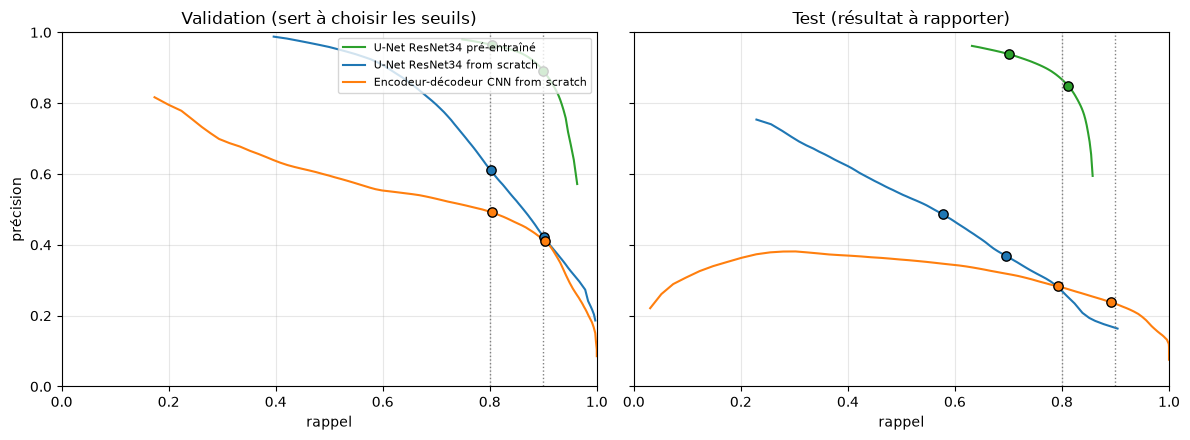

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
colors = dict(zip(MODELS, ["tab:green", "tab:blue", "tab:orange"]))
for ax, split in zip(axes, ["val", "test"]):
    for name in MODELS:
        sw = SWEEPS[name][split]
        ax.plot(sw["recall"], sw["precision"], color=colors[name], label=name)
        for t in TARGET_RECALLS:
            thr, _ = pick_threshold(SWEEPS[name]["val"], t)
            pt = sw.loc[(sw["thr"] - thr).abs().idxmin()]
            ax.scatter(pt["recall"], pt["precision"], color=colors[name], s=45, zorder=3, edgecolor="black")
    for t in TARGET_RECALLS: ax.axvline(t, color="gray", ls=":", lw=1)
    ax.set_title("Validation (sert à choisir les seuils)" if split == "val" else "Test (résultat à rapporter)")
    ax.set_xlabel("rappel"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
axes[0].set_ylabel("précision"); axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "courbes_precision_rappel.png"), dpi=110); plt.show()

## 7. Taille et temps d'inférence
Mesure sur CPU, une image 512×288, après échauffement, moyenne de 30 passages. À exécuter quand rien d'autre ne tourne.

In [11]:
x_inf = torch.randn(1, 3, IMG_H, IMG_W, device=DEVICE)
perf_rows = []
for name, m in loaded.items():
    m.eval()
    with torch.no_grad():
        for _ in range(3): m(x_inf)
        t0 = time.time()
        for _ in range(30): m(x_inf)
    perf_rows.append({"Modèle": name,
                      "Paramètres (M)": sum(p.numel() for p in m.parameters()) / 1e6,
                      "Fichier .pt (Mo)": os.path.getsize(MODELS[name]["path"]) / 1e6,
                      "Inférence (ms/image)": (time.time() - t0) / 30 * 1000})
perf = pd.DataFrame(perf_rows)
print("Périphérique :", DEVICE)
display(perf.round(2))

Périphérique : cpu


,Modèle,Paramètres (M),Fichier .pt (Mo),Inférence (ms/image)
0,U-Net ResNet34 pré-entraîné,24.44,97.91,225.16
1,U-Net ResNet34 from scratch,24.44,97.91,152.28
2,Encodeur-décodeur CNN from scratch,1.75,7.04,49.53


## 8. Synthèse et sauvegarde

In [12]:
bo.round(4).to_csv(os.path.join(OUT_DIR, "comparaison_bo.csv"), index=False, encoding="utf-8-sig")
perf.round(3).to_csv(os.path.join(OUT_DIR, "taille_et_temps.csv"), index=False, encoding="utf-8-sig")
with open(os.path.join(OUT_DIR, "comparaison_bo.json"), "w", encoding="utf-8") as f:
    json.dump({"target_recalls": TARGET_RECALLS, "detect_recall": DETECT_RECALL, "device": DEVICE,
               "comparaison": bo.round(4).to_dict(orient="records"), "taille_et_temps": perf.round(3).to_dict(orient="records")},
              f, indent=2, ensure_ascii=False)
print("Fichiers sauvegardés dans", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

Fichiers sauvegardés dans c:\Projects\deep_learning\RoadAnomaly\RoadAnomaly\outputs_comparaison_bo : ['comparaison_bo.csv', 'comparaison_bo.json', 'courbes_precision_rappel.png', 'taille_et_temps.csv']


## 9. Lecture pour le BO (à compléter avec vos chiffres)

1. **Rappel et précision au rappel visé.** Pour un rappel visé de 80 %, quel modèle garde la meilleure précision ? Une précision basse veut dire beaucoup de fausses alertes pour chaque obstacle trouvé.
2. **Cible atteinte ou non.** Si un modèle n'atteint pas le rappel visé sur la validation (colonne « Cible atteinte »), il ne convient pas à ce BO, quelle que soit sa précision.
3. **Obstacles détectés et fausses alertes.** Ces deux colonnes se lisent plus facilement que les pixels : combien d'images sur 12 ont leur obstacle retrouvé, et quelle part de l'image est signalée à tort.
4. **Taille et vitesse.** Le plus petit modèle est le plus rapide, mais n'est utile que s'il garde un rappel suffisant. Un compromis acceptable se justifie avec les chiffres de la section 7.
5. **Limites à écrire dans le rapport.** Seulement 12 images de test : un écart de quelques points entre deux modèles n'est pas significatif. Les seuils sont choisis sur 12 images de validation. Le temps mesuré est celui d'un CPU de PC portable, pas d'un système embarqué.

**Décision pour l'app :** le modèle déployé pour ce BO est celui qui atteint le rappel visé avec la meilleure précision, en tenant compte du temps d'inférence.

In [13]:
name = "U-Net ResNet34 pré-entraîné"
thr, _ = pick_threshold(SWEEPS[name]["val"], 0.90)
_, per_img, _ = evaluate(test_names, PROBS[name]["test"], thr)
display(per_img.sort_values("recall")[["name", "recall", "precision", "iou"]].round(3))

,name,recall,precision,iou
11,vehicle02_Broadmoor_Cones_Skidloader,0.076,0.728,0.074
8,obstacles04_cardboard_czech_hedgehog,0.760,0.842,0.666
3,animals19_Porte_de_Roubaix,0.789,0.810,0.666
1,animals13_jeune_bovin_sur_la_route,0.830,0.855,0.727
7,cones07,0.834,0.889,0.756
10,obstacles11_boulder5,0.909,0.860,0.792
9,obstacles09_boulder3,0.917,0.937,0.863
4,animals26_Unnamed_Road_Kazakhstan,0.921,0.701,0.662
5,animals30,0.927,0.792,0.745
6,cones04_Federation,0.936,0.681,0.651


In [14]:
import statistics
for rep in range(2):
    for name, m in loaded.items():
        with torch.no_grad():
            for _ in range(10): m(x_inf)
            ts = []
            for _ in range(50):
                t0 = time.time(); m(x_inf); ts.append((time.time() - t0) * 1000)
        print(f"essai {rep+1} | {name:38s} | médiane {statistics.median(ts):.0f} ms")

essai 1 | U-Net ResNet34 pré-entraîné            | médiane 119 ms
essai 1 | U-Net ResNet34 from scratch            | médiane 124 ms
essai 1 | Encodeur-décodeur CNN from scratch     | médiane 50 ms
essai 2 | U-Net ResNet34 pré-entraîné            | médiane 120 ms
essai 2 | U-Net ResNet34 from scratch            | médiane 223 ms
essai 2 | Encodeur-décodeur CNN from scratch     | médiane 96 ms
